# Lap-time OCP results log

One minimum lap-time solve from `post/<name>.pkl` (written by `laptime_core/history.py` for `omc2casadi_opt.run_min_laptime` and `fmu_opt.run_min_laptime`), plotted with `plotting/PlotHelpers.py`. Everything is looked up by name from the pickle.

Rebuild for another run: `python -B omc2casadi_opt/build_run_notebook.py <name>` (no name = newest), or change `pkl_file` below and re-run the notebook.

In [1]:
%matplotlib inline
import importlib
import os
import pickle
import sys
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

# repo root, whether the kernel starts in omc2casadi_opt/notebooks/ or the repo
ROOT = Path.cwd()
while not (ROOT/'laptime_core').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import plotting.PlotHelpers as plot_helpers
plot_helpers = importlib.reload(plot_helpers)

# Bind plotting functions from the freshly reloaded module.
plot_final_iteration_profiles_with_bounds = plot_helpers.plot_final_iteration_profiles_with_bounds
plot_ipopt_convergence_panels             = plot_helpers.plot_ipopt_convergence_panels
plot_top5_infeasibility_stackplot         = plot_helpers.plot_top5_infeasibility_stackplot
plot_track_bounds_with_trajectory         = plot_helpers.plot_track_bounds
plot_iteration_trace_dashboard            = plot_helpers.plot_iteration_trace_dashboard
plot_iteration_traces                     = plot_helpers.plot_iteration_traces
plot_speed_and_guess                      = plot_helpers.plot_speed_and_guess
plot_slip_utilisation                     = plot_helpers.plot_slip_utilisation
plot_timing                               = plot_helpers.plot_timing
plot_defects_vs_s                         = plot_helpers.plot_defects_vs_s

# schema helpers: everything is looked up BY NAME from the pickle
signal       = plot_helpers.signal
bounds       = plot_helpers.bounds
stateNames   = plot_helpers.stateNames
controlNames = plot_helpers.controlNames

In [2]:
# Which run to load.
#   pkl_file = None            -> newest .pkl in post/ (by modification time)
#   pkl_file = "name"          -> post/name.pkl  (.pkl optional)
#   pkl_file = "/abs/path.pkl" -> that file
pkl_file = None

post_dir = ROOT/'post'

if pkl_file is None:
    candidates = list(post_dir.glob('*.pkl'))
    if not candidates:
        raise FileNotFoundError(f'No .pkl files found in {post_dir}')
    # newest by modification time, NOT lexicographic order
    pkl_path = max(candidates, key=lambda f: f.stat().st_mtime)
else:
    pkl_path = Path(pkl_file).expanduser()
    if not pkl_path.is_absolute() and not pkl_path.exists():
        pkl_path = post_dir/pkl_path          # bare name -> look in post/
    if pkl_path.suffix != '.pkl':
        pkl_path = pkl_path.with_suffix('.pkl')
    if not pkl_path.exists():
        raise FileNotFoundError(f'{pkl_path} not found')

pkl_file = str(pkl_path)

with open(pkl_file, 'rb') as fh:
    output_data = pickle.load(fh)

print(f'Loaded {pkl_path.name}')
print(f'  {pkl_path}')
print(f'  modified {datetime.fromtimestamp(pkl_path.stat().st_mtime):%Y-%m-%d %H:%M:%S}'
      f'   {pkl_path.stat().st_size/1e6:.1f} MB')
print()

# available runs, newest first
runs = sorted(post_dir.glob('*.pkl'), key=lambda f: f.stat().st_mtime, reverse=True)
print(f'{len(runs)} run(s) in post/:')
for f in runs[:10]:
    mark = ' <-- loaded' if f == pkl_path else ''
    print(f'  {datetime.fromtimestamp(f.stat().st_mtime):%Y-%m-%d %H:%M}  {f.name}{mark}')
print()

meta = output_data['meta']
settings = output_data.get('settings', {}) or {}
cons = meta['config'].get('constraints', {})
timing = output_data.get('timing', {}) or {}
print(f"track     {meta.get('track')}")
print(f"model     {meta.get('model')}   vehicle={settings.get('vehicle')}")
print(f"tire      {plot_helpers.slip_model(meta['config'])}   slip_peak {cons.get('slip_peak')}")
print(f"nodes     N={meta.get('N')}  degree={meta.get('degree')}  nx={meta.get('nx')}  nu={meta.get('nu')}")
print(f"status    {meta.get('status')}   iterations {meta.get('iterCount')}"
      f"   (exact Hessian from iteration {meta.get('phase2Start')})")
print(f"lap time  {meta.get('lapTime'):.4f} s"
      + (f"   (RK4 check {output_data['lapTimeRK4']:.4f} s)" if output_data.get('lapTimeRK4') is not None else ''))
if timing.get('wall') is not None:
    print(f"wall      {timing['wall']:.0f} s   {timing['wall']/max(meta.get('iterCount') or 1, 1):.2f} s/iter"
          f"   threads={settings.get('threads')}  linear_solver={settings.get('linear_solver')}")
print(f"frames    {len(output_data.get('frames', []))} (stride {meta.get('stride')})")

print('\nKeys:', list(output_data.keys()))

Loaded Catalunya_N465_20261105_094359_casadi.pkl
  c:\Users\amcpo\Beluga\post\Catalunya_N465_20261105_094359_casadi.pkl
  modified 2026-11-05 10:15:39   26.6 MB

2 run(s) in post/:
  2026-11-05 10:15  Catalunya_N465_20261105_094359_casadi.pkl <-- loaded
  2026-11-01 13:29  Catalunya_N465_20261101_131101_casadi.pkl

track     Catalunya
model     AlyssaModel.Experiments.OptimalControlFMU (fmu/AlyssaVehicle.fmu)   vehicle=casadi
tire      brush   slip_peak [0.1125, 0.1125, 1.0]
nodes     N=465  degree=2  nx=34  nu=3
status    Solve_Succeeded   iterations 293   (exact Hessian from iteration 219)
lap time  83.0907 s   (RK4 check 83.0884 s)
wall      1537 s   5.25 s/iter   threads=10  linear_solver=lapacklu
frames    295 (stride 1)

Keys: ['meta', 'refX', 'refY', 'refPsi', 'baseTrack', 's', 'h', 'kappa', 'nMin', 'nMax', 'convergence', 'timing', 'frames', 'derived', 'final', 'defects', 'vGuess', 'reference', 'settings', 'lapTimeRK4']


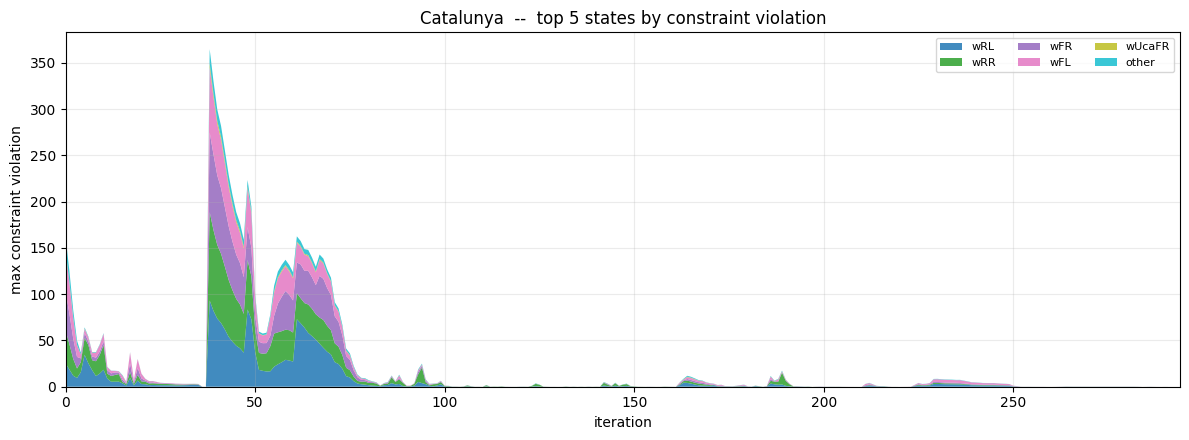

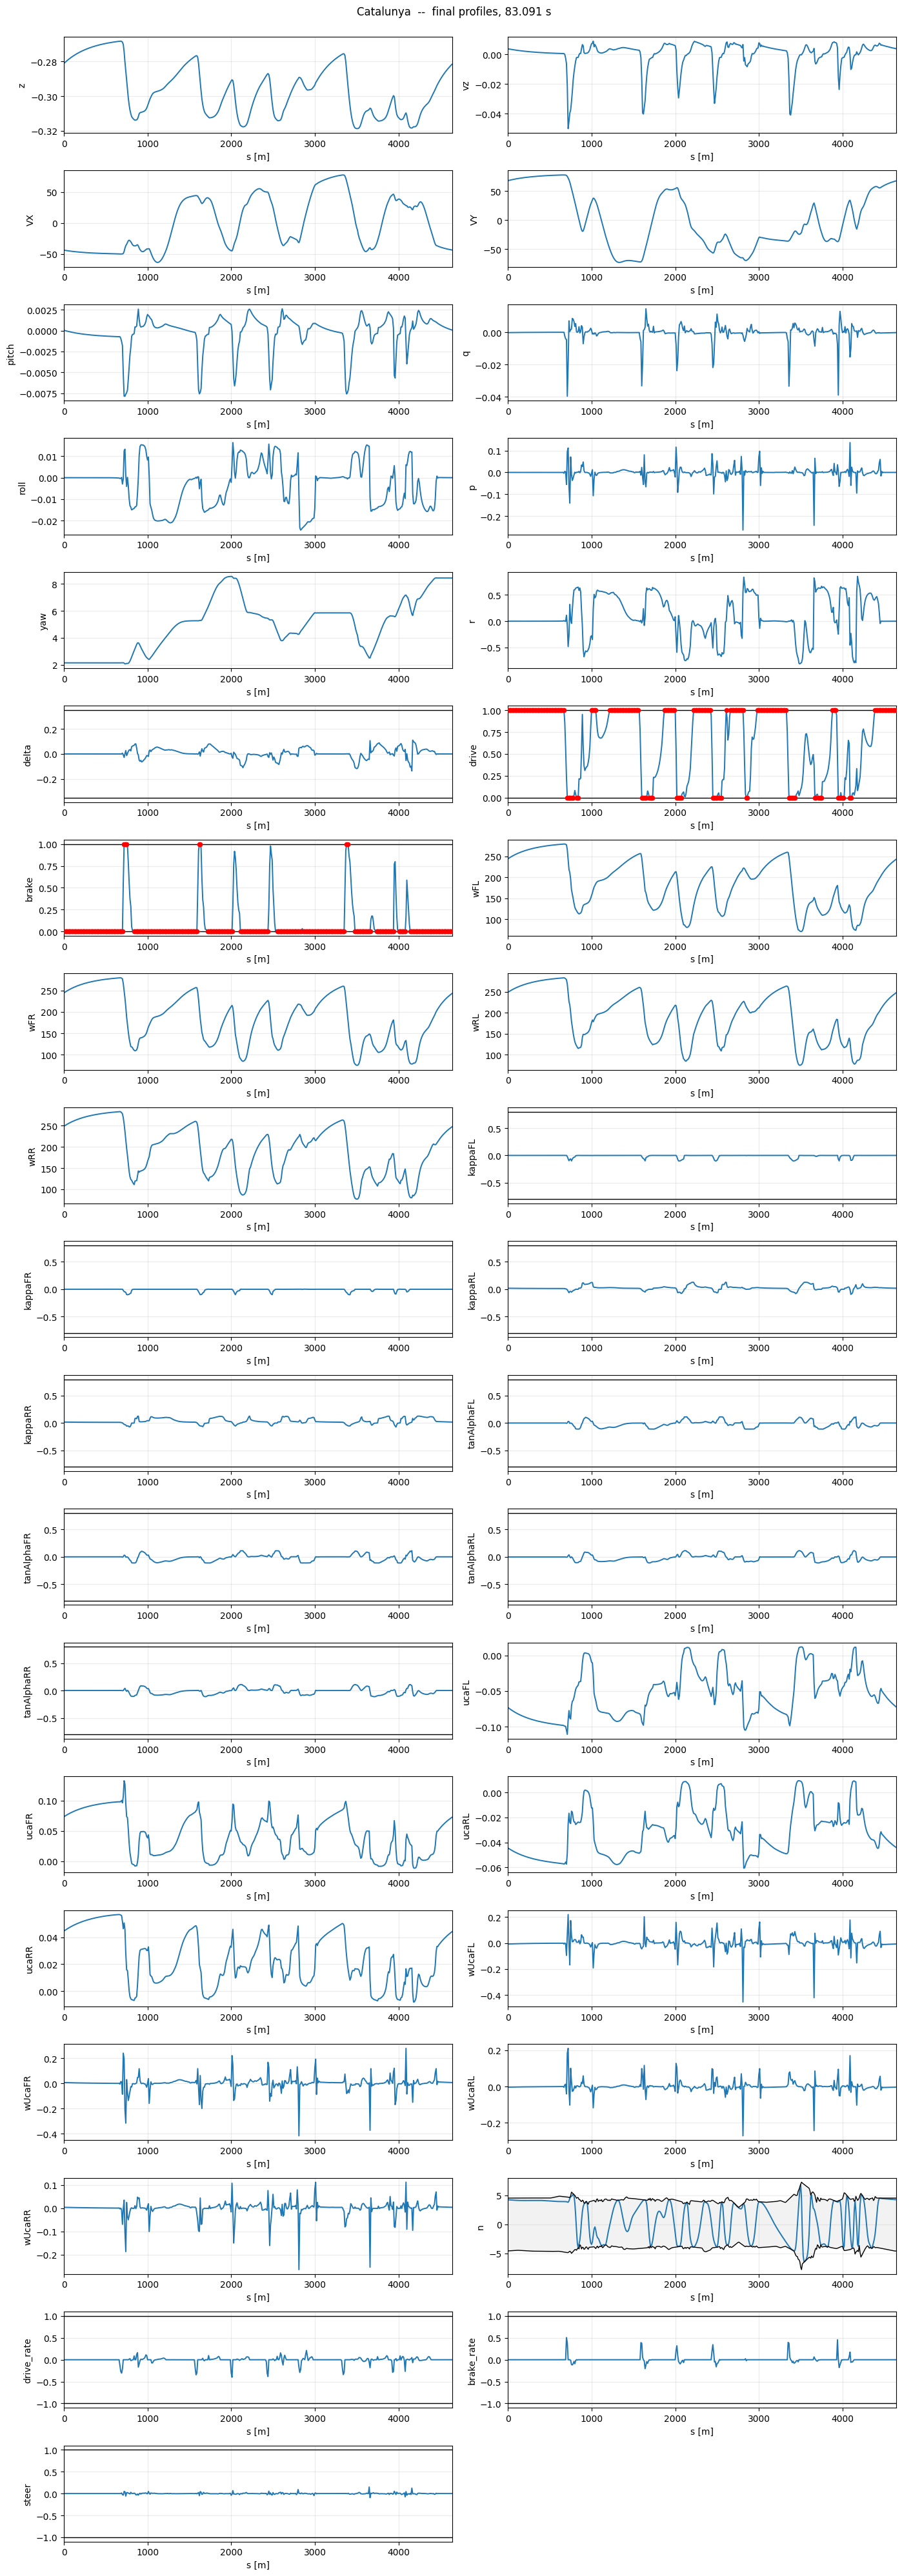

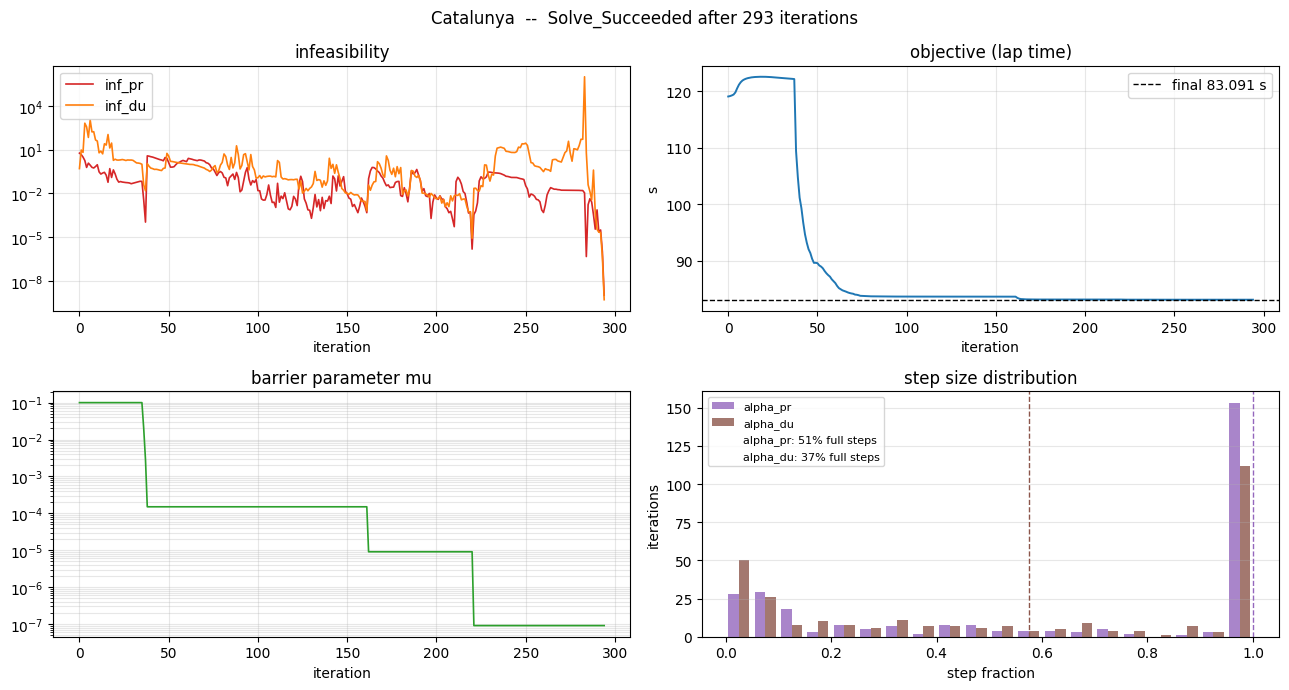

In [3]:
# 1) Stackplots: top-5 contributors to inf_pr and inf_du
begin_iter = 0  # set >0 to zoom into later iterations
fig1, axes1 = plot_top5_infeasibility_stackplot(output_data, begin_iter=begin_iter)
plt.show()

# 2) Final-iteration node profiles with constraint bounds
fig2, axes2 = plot_final_iteration_profiles_with_bounds(output_data)
plt.show()

# 3) IPOPT convergence panels
fig3, axes3 = plot_ipopt_convergence_panels(output_data)
plt.show()

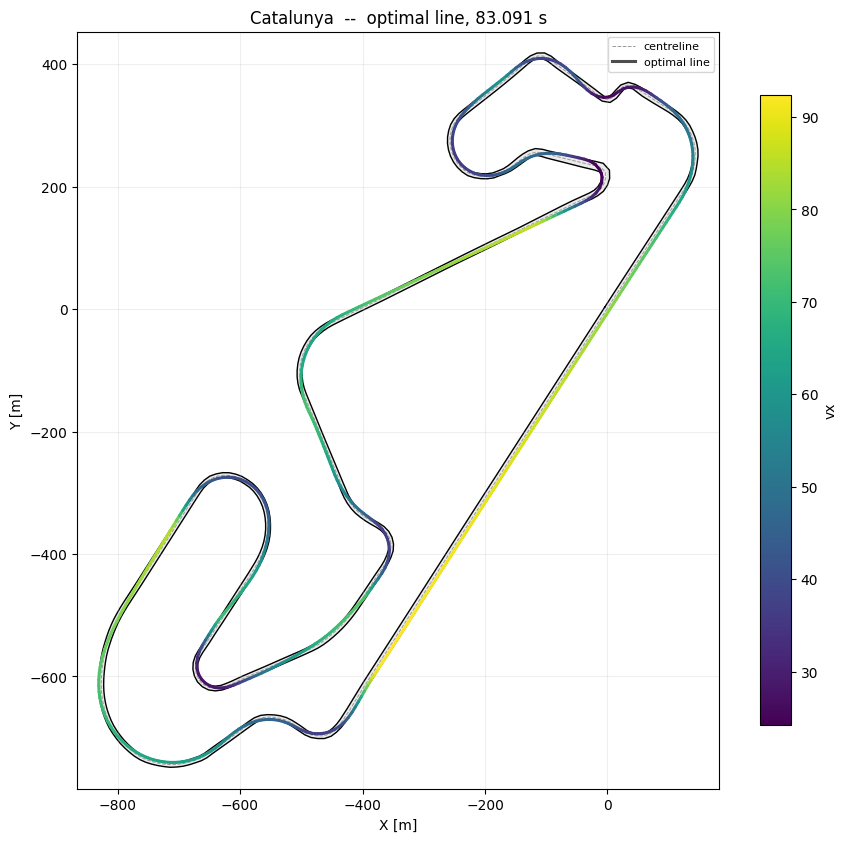

In [4]:
# 4) Circuit bounds and optimal trajectory
fig4, ax4 = plot_track_bounds_with_trajectory(output_data)
plt.show()

In [5]:
# 5) Interactive trace dashboard across all iterations
#    (widgets are live only in a running kernel: re-run this cell after opening the notebook)
dashboard = plot_iteration_trace_dashboard(output_data)
display(dashboard)

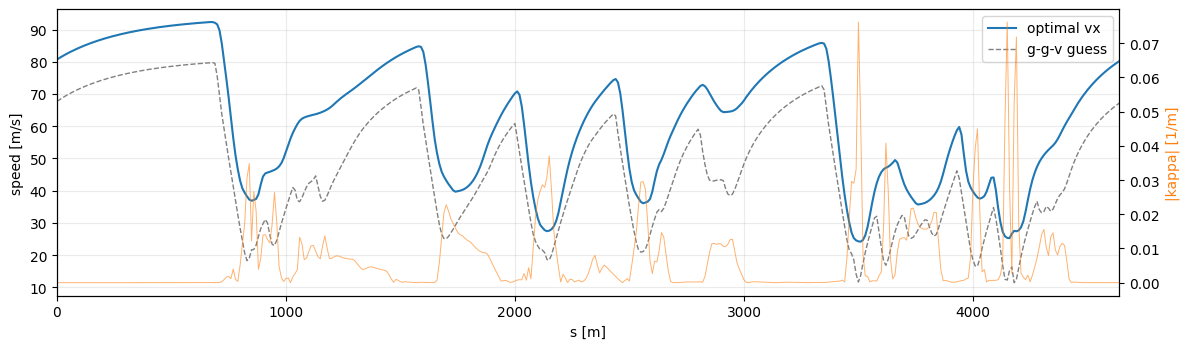

states  : ['z', 'vz', 'VX', 'VY', 'pitch', 'q', 'roll', 'p', 'yaw', 'r', 'delta', 'drive', 'brake', 'wFL', 'wFR', 'wRL', 'wRR', 'kappaFL', 'kappaFR', 'kappaRL', 'kappaRR', 'tanAlphaFL', 'tanAlphaFR', 'tanAlphaRL', 'tanAlphaRR', 'ucaFL', 'ucaFR', 'ucaRL', 'ucaRR', 'wUcaFL', 'wUcaFR', 'wUcaRL', 'wUcaRR', 'n']
controls: ['drive_rate', 'brake_rate', 'steer']


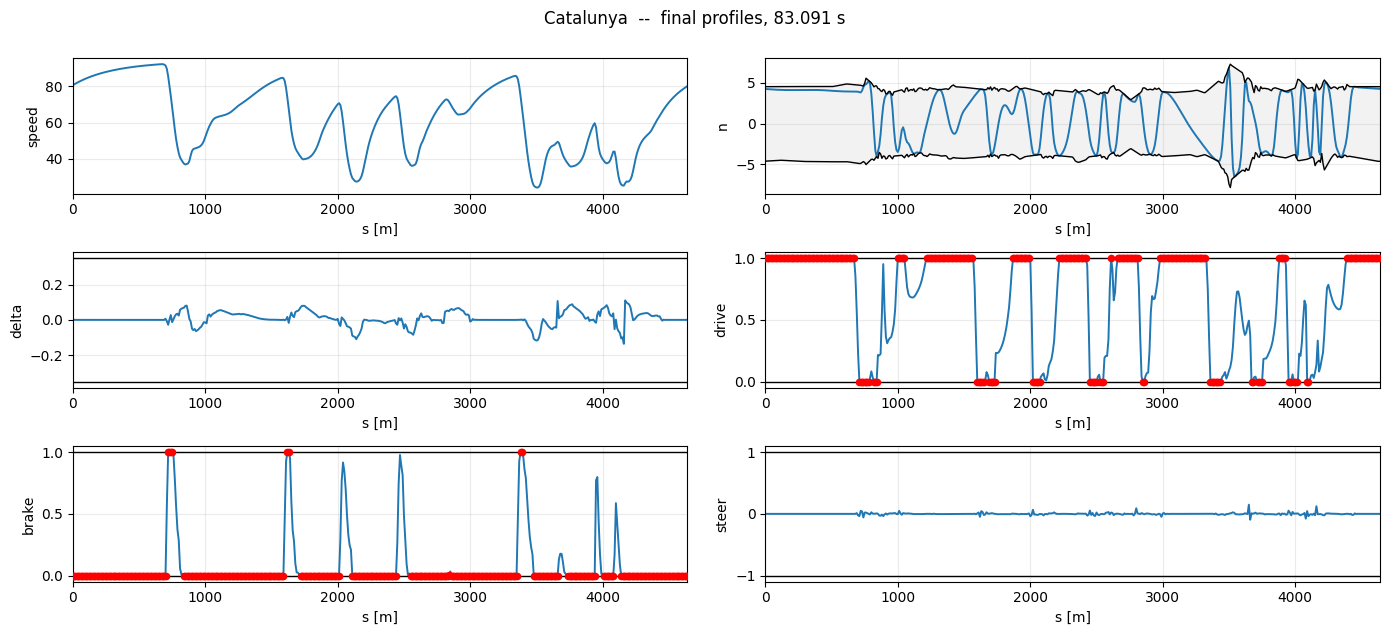

In [6]:
# 6) Speed profile against the initial guess, and the states/controls that
#    matter most. Everything is looked up BY NAME -- any state, control or derived
#    signal of the pickle works here.
fig5, ax5 = plot_speed_and_guess(output_data)
plt.show()

print('states  :', stateNames(output_data))
print('controls:', controlNames(output_data))

# any subset, by name
fig6, axes6 = plot_final_iteration_profiles_with_bounds(
    output_data, names=['speed', 'n', 'delta', 'drive', 'brake', 'steer'], ncols=2)
plt.show()

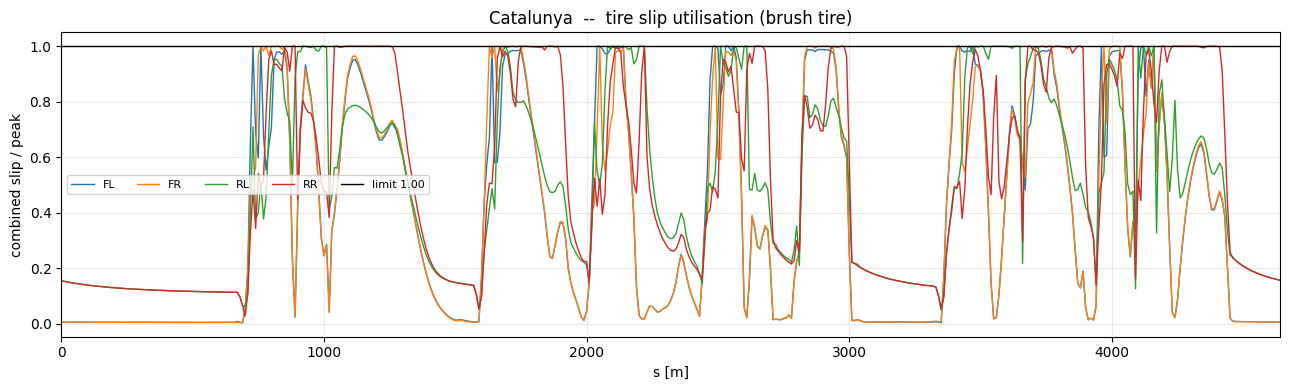

In [7]:
# 7) Tire slip use against the limit (formula from the run's tire model: MF or brush)
fig7, ax7 = plot_slip_utilisation(output_data)
plt.show()

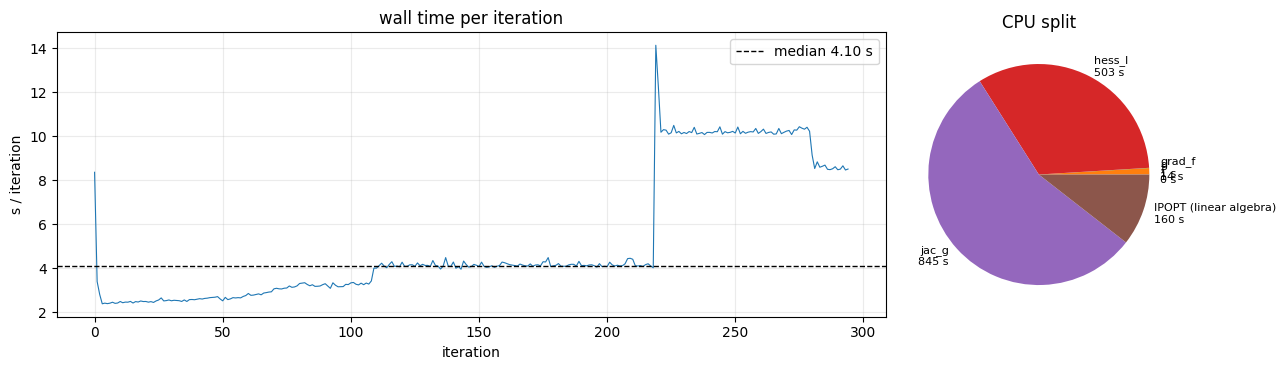

In [8]:
# 8) Timing: seconds per IPOPT iteration, function evaluations vs linear algebra
fig8, axes8 = plot_timing(output_data)
plt.show()

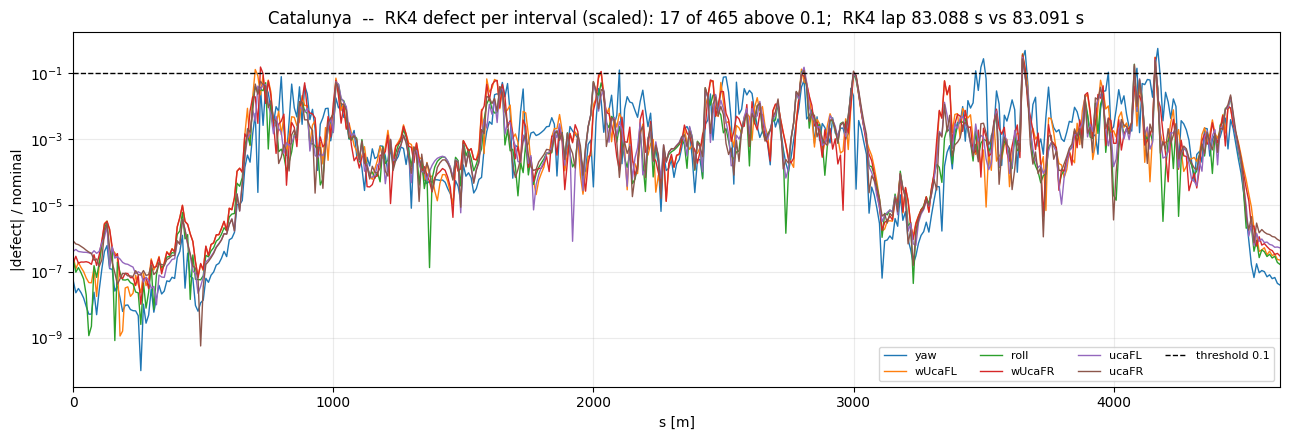

In [9]:
# 9) Fine-RK4 defects per interval along the lap
if output_data.get('defects') is not None:
    fig9, ax9 = plot_defects_vs_s(output_data)
    plt.show()
else:
    print('no defects in this run')